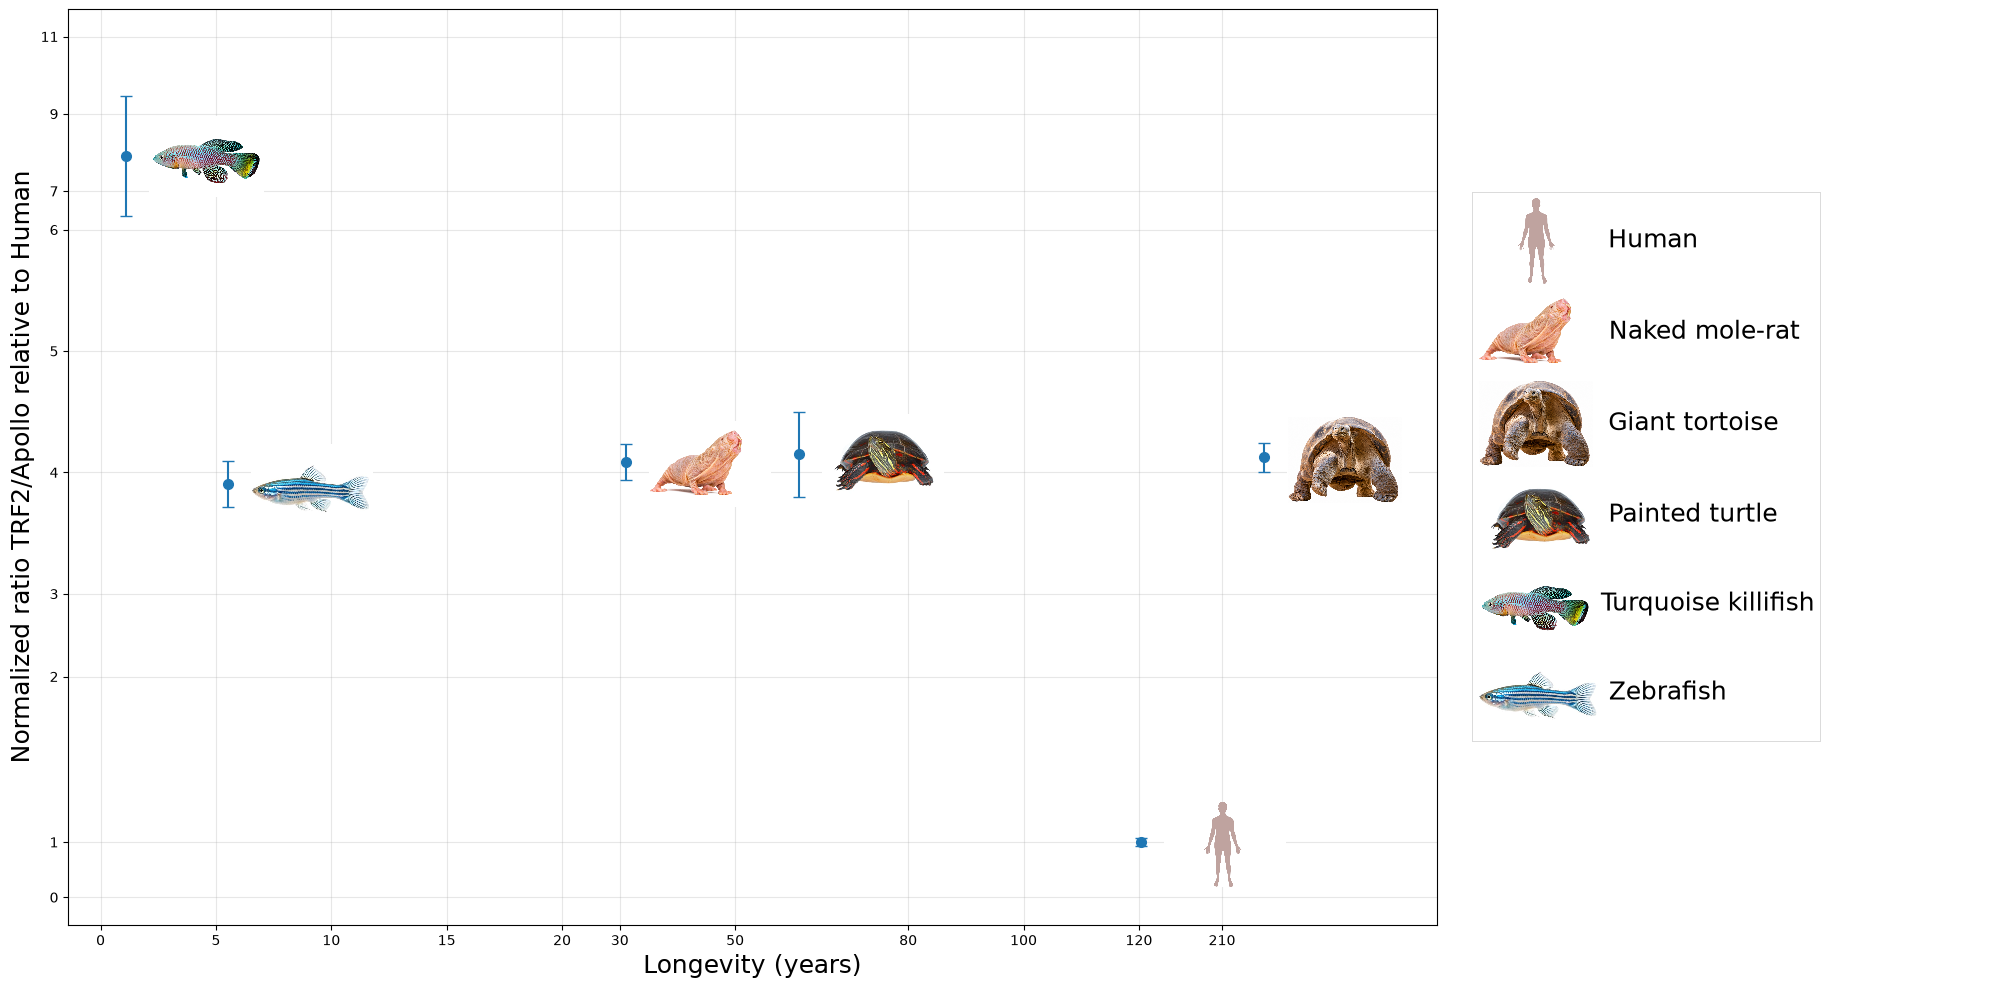

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox, TextArea, HPacker, VPacker, AnchoredOffsetbox
from matplotlib.gridspec import GridSpec
import os

species = [
    'Human',
    'Naked mole-rat',
    'Giant tortoise',
    'Painted turtle',
    'Turquoise killifish',
    'Zebrafish'
]

longevity = [122.5, 31, 255, 61, 1.1, 5.5]
average = [1, 4.0873202528942, 4.125052211, 4.148217735, 7.905123916, 3.903317492]
sd = [0.13955531501634, 0.660716064166307, 0.527604161, 1.530780283, 2.180656653, 0.8319564]

df = pd.DataFrame({'Species': species, 'Longevity': longevity, 'Average': average, 'Sd': sd})

img_map = {
    'Human': 'Hs1.png',
    'Naked mole-rat': 'Hg.png',
    'Giant tortoise': 'Ca.png',
    'Painted turtle': 'Cp.png',
    'Turquoise killifish': 'Nf.png',
    'Zebrafish': 'Dr.png',
}
def x_transform(x):
    if x <= 20:
        return x * 2.0
    elif x <= 120:
        return 40 + (x - 20) * 0.5
    else:
        return 90 + (x - 120) * 0.08

def y_transform(y):
    if y <= 1:
        return y
    elif y <= 2:
        return 1 + (y - 1) * 3.0
    elif y <= 3:
        return 4.0 + (y - 2) * 1.5
    elif y <= 6:
        return 5.5 + (y - 3) * 2.2
    else:
        return 12.1 + (y - 6) * 0.7

x_plot = df['Longevity'].apply(x_transform)
y_plot = df['Average'].apply(y_transform)

fig = plt.figure(figsize=(20, 10))
gs = GridSpec(1, 2, width_ratios=[3.2, 1.2], figure=fig)
ax = fig.add_subplot(gs[0, 0])
ax_tbl = fig.add_subplot(gs[0, 1])

ax.errorbar(
    x_plot, y_plot,
    yerr=df['Sd']*0.5,
    fmt='o',
    capsize=4,
    alpha=1.0,
    color='tab:blue',
    ecolor='tab:blue',
    elinewidth=1.5,
    markersize=7
)
x_shift = 2
y_shift = 0.5

for xi, yi, (_, row) in zip(x_plot, y_plot, df.iterrows()):
    img_file = img_map.get(row['Species'])
    try:
        img = Image.open(img_file).convert('RGBA')
        im = OffsetImage(img, zoom=0.09)
        ab = AnnotationBbox(
            im,
            (xi + x_shift, yi + y_shift),
            frameon=False,
            box_alignment=(0, 0.85)
        )
        ax.add_artist(ab)
    except Exception:
        ax.annotate(row['Species'], (xi + x_shift, yi + y_shift), fontsize=12, va='center')

xticks = [0, 5, 10, 15, 20, 30, 50, 80, 100, 120, 210]
ax.set_xticks([x_transform(v) for v in xticks])
ax.set_xticklabels([str(v) for v in xticks])

yticks = [0, 1, 2, 3, 4, 5, 6, 7, 9, 11]
ax.set_yticks([y_transform(v) for v in yticks])
ax.set_yticklabels([str(v) for v in yticks])


ax.set_xlim(x_transform(min(longevity)) - 5, x_transform(max(longevity)) + 15)
ax.set_ylim(y_transform(0) - 0.5, y_transform(11) + 0.5)

ax.set_xlabel('Longevity (years)', fontsize=18)
ax.set_ylabel('Normalized ratio TRF2/Apollo relative to Human', fontsize=18)
ax.set_title('', fontsize=20)
ax.grid(True, alpha=0.3)

ax_tbl.axis('off')
rows = []
for sp in species:
    img_file = img_map[sp]
    if os.path.exists(img_file):
        img = Image.open(img_file).convert('RGBA')
        icon_part = OffsetImage(img, zoom=0.09)
    else:
        icon_part = TextArea('■', textprops=dict(size=16))

    txt = TextArea(sp, textprops=dict(size=18))   # bỏ "ứng với 2.png"
    rowbox = HPacker(children=[icon_part, txt], align='center', pad=0, sep=6)
    rows.append(rowbox)

legend_box = VPacker(children=rows, align='left', pad=0, sep=4)
anchored = AnchoredOffsetbox(
    loc='center left',
    child=legend_box,
    pad=0.4,
    frameon=True,
    bbox_to_anchor=(0.0, 0.5),
    bbox_transform=ax_tbl.transAxes,
    borderpad=0.4
)
anchored.patch.set_facecolor('white')
anchored.patch.set_edgecolor('#d3d3d3')
anchored.patch.set_linewidth(0.5)
ax_tbl.add_artist(anchored)
ax_tbl.add_artist(anchored)

plt.tight_layout()
plt.show()

In [3]:
fig.savefig("scatter plot heat map", dpi=600, bbox_inches="tight", pad_inches=0.1)
